In [30]:
import pandas as pd
from sklearn.datasets import fetch_california_housing



1. Data Loading and Preprocessing 
    ● Loading the Dataset:
        ○ Load the California Housing dataset using the fetch_california_housing function from            sklearn.
        ○ Convert the dataset into a pandas DataFrame for easier handling.

In [31]:
# Load the California Housing dataset
california_housing = fetch_california_housing()
# Convert features to a pandas DataFrame
housing_df = pd.DataFrame(
    california_housing.data,
    columns=california_housing.feature_names
)
housing_df["MedHouseVal"] = california_housing.target

print(housing_df.head())
print(housing_df.shape)

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
(20640, 9)


● Preprocessing:
    ○ Handle missing values, if any.
    ○ Perform feature scaling using standardization or normalization, explaining the
      choice.
    ○ Conduct exploratory data analysis (EDA) to understand the features,
      distributions, and correlations.

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Check missing values
print(housing_df.isnull().sum())

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [38]:
features = housing_df.drop(columns="MedHouseVal")
target = housing_df["MedHouseVal"]

imputer = SimpleImputer(strategy="median")
features_imputed = imputer.fit_transform(features)
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features_imputed)

# Convert scaled features back to a DataFrame
scaled_df = pd.DataFrame(features_scaled, columns=features.columns)
scaled_df["MedHouseVal"] = target.values

             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
25%        2.563400     18.000000      4.440716      1.006079    787.000000   
50%        3.534800     29.000000      5.229129      1.048780   1166.000000   
75%        4.743250     37.000000      6.052381      1.099526   1725.000000   
max       15.000100     52.000000    141.909091     34.066667  35682.000000   

           AveOccup      Latitude     Longitude   MedHouseVal  
count  20640.000000  20640.000000  20640.000000  20640.000000  
mean       3.070655     35.631861   -119.569704      2.068558  
std       10.386050      2.135952      2.003532      1.153956  
min        0.692308     32.54000

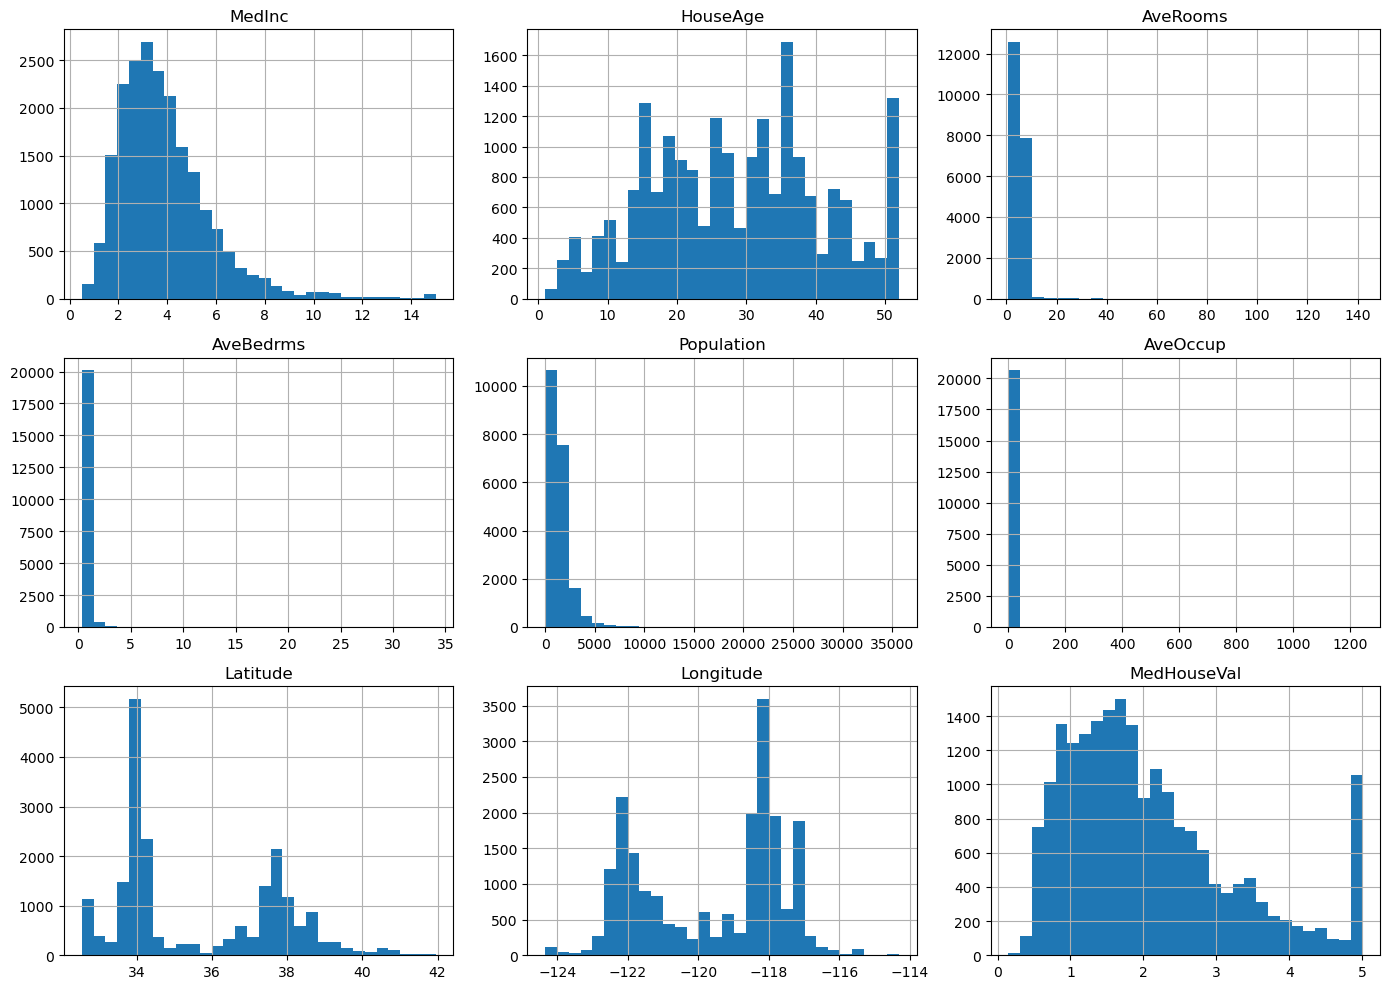

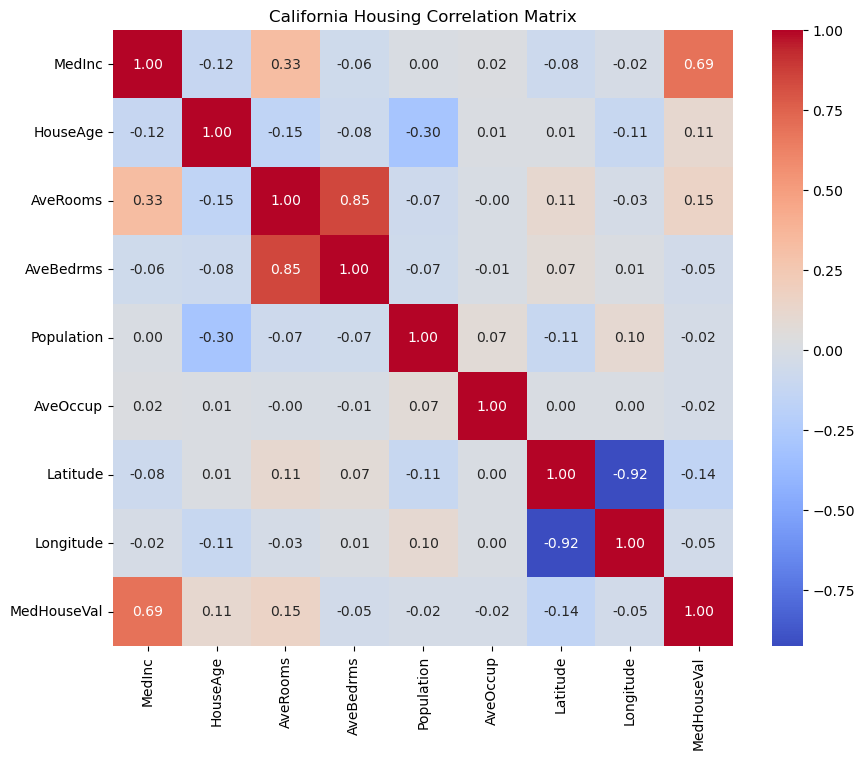

In [39]:
print(housing_df.describe())

# Distribution plots
housing_df.hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

# Correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(
    housing_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("California Housing Correlation Matrix")
plt.show()


2. Regression Algorithm Implementation:
   Implement the following regression algorithms:
    ● Linear Regression
    ● Decision Tree Regressor
    ● Random Forest Regressor
    ● Gradient Boosting Regressor
    ● Support Vector Regressor (SVR)

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

# housing_df was created from the California Housing dataset
X = housing_df.drop(columns="MedHouseVal")
y = housing_df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=100, random_state=42, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingRegressor(random_state=42))
    ]),
    "SVR": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVR(kernel="rbf"))
    ])
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "RMSE": mean_squared_error(y_test, predictions) ** 0.5,
        "R² Score": r2_score(y_test, predictions)
    })

    print(f"\n{name} predictions:")
    print(predictions[:5])

results_df = pd.DataFrame(results).sort_values(
    by="R² Score", ascending=False
)

print("\nModel comparison:")
print(results_df)


Linear Regression predictions:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725]

Decision Tree predictions:
[0.414   1.203   5.00001 2.17    2.257  ]

Random Forest predictions:
[0.5095    0.74161   4.9232571 2.52961   2.27369  ]

Gradient Boosting predictions:
[0.50518761 1.09334601 4.24570956 2.54517359 2.27910301]

SVR predictions:
[0.51647228 1.56842925 3.59780295 2.49108208 2.56880838]

Model comparison:
               Model      RMSE  R² Score
2      Random Forest  0.505340  0.805123
3  Gradient Boosting  0.542215  0.775645
4                SVR  0.597498  0.727563
1      Decision Tree  0.703729  0.622076
0  Linear Regression  0.745581  0.575788


3. Model Evaluation and Comparison 
● Evaluate the performance of each algorithm using:
○ Mean Squared Error (MSE)
○ Mean Absolute Error (MAE)
○ R-squared Score (R2)

In [45]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import pandas as pd

results = []

for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)

    # Predict median house prices
    predictions = model.predict(X_test)

    # Evaluate performance
    mse = mean_squared_error(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MSE": mse,
        "MAE": mae,
        "R2 Score": r2
    })

# Display comparison table
results_df = pd.DataFrame(results).sort_values(
    by="R2 Score",
    ascending=False
)

print(results_df)

               Model       MSE       MAE  R2 Score
2      Random Forest  0.255368  0.327543  0.805123
3  Gradient Boosting  0.293997  0.371643  0.775645
4                SVR  0.357004  0.398599  0.727563
1      Decision Tree  0.495235  0.454679  0.622076
0  Linear Regression  0.555892  0.533200  0.575788


Best-performing model: Random Forest Regressor
Random Forest is the best model because it has the lowest MSE (0.2554) and MAE (0.3275), as well as the highest R² score (0.8051). It explains about 80.5% of the variation in median house values. Its ensemble of trees captures non-linear relationships and interactions between income, location, population, and housing characteristics while reducing the overfitting risk of a single decision tree.
Worst-performing model: Linear Regression
Linear Regression is the weakest model here because it has the highest MSE (0.5559) and MAE (0.5332) and the lowest R² score (0.5758). It assumes the relationship between features and house price is mainly linear. California housing values have more complex non-linear patterns—especially from geographical features such as latitude and longitude—so this simple assumption limits its predictive accuracy.


10:53 AM